# EduPulse — dataset exploration

EduPulse is an early-warning idea: use signals a college already records
(attendance, internal assessment, engagement) to flag students who may be
falling behind, while there is still time to intervene.

This notebook is a small proof of concept on public datasets. It:

1. loads every dataset in `datasets/`
2. inspects columns and missing values
3. cleans what actually needs cleaning
4. picks the dataset that fits EduPulse best
5. defines a simple target and trains two models
6. compares them and explains the predictions

It is not a production system, and the data is not VIT data unless a dataset
says so.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42
DATA_DIR = Path("datasets")

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 3.0.5 | numpy 2.5.3


## 1. Load the datasets

Every CSV in `datasets/` is loaded as-is. No name assumptions beyond the file
stem, so adding a dataset is just dropping a file in the folder.

In [2]:
datasets = {path.stem: pd.read_csv(path) for path in sorted(DATA_DIR.glob("*.csv"))}

for name, df in datasets.items():
    print(f"{name:<40} {df.shape[0]:>7,} rows x {df.shape[1]:>2} columns")

engineering_student_journey                2,000 rows x 24 columns
student_academic_performance_cse           1,194 rows x 31 columns
student_performance_attendance            25,000 rows x 16 columns
student_performance_tamilnadu              5,000 rows x 22 columns


## 2. Inspect columns and missing values

Enough to know what each file offers and what will need repair.

In [3]:
for name, df in datasets.items():
    missing = df.isna().sum()
    missing = missing[missing > 0]
    missing_text = ", ".join(f"{col} ({count})" for col, count in missing.items()) or "none"
    print(f"--- {name}")
    print("columns :", ", ".join(df.columns))
    print("missing :", missing_text)
    print()

--- engineering_student_journey
columns : Student ID, Name, Age, Gender, Branch, Average GPA, Backlogs, Attendance (%), Clubs, Skills, Internship Done, Internship Domain, Placement Status, Placement Domain, CTC (LPA), Alumni Path, Sem1 GPA, Sem2 GPA, Sem3 GPA, Sem4 GPA, Sem5 GPA, Sem6 GPA, Sem7 GPA, Sem8 GPA
missing : Student ID (1), Age (1), Gender (1), Branch (1), Average GPA (1), Backlogs (1), Attendance (%) (1), Clubs (1), Skills (1), Internship Done (1), Internship Domain (1018), Placement Status (1), Placement Domain (968), CTC (LPA) (1), Alumni Path (968), Sem1 GPA (1), Sem2 GPA (1), Sem3 GPA (1), Sem4 GPA (1), Sem5 GPA (1), Sem6 GPA (1), Sem7 GPA (1), Sem8 GPA (1)

--- student_academic_performance_cse
columns : University Admission year, Gender, Age, H.S.C passing year, Program, Current Semester, Do you have meritorious scholarship ?, Do you use University transportation?, How many hour do you study daily?, How many times do you seat for study in a day?, What is your preferable

## 3. Clean the data

The dataset we end up modelling on stores attendance as **text**, mixing plain
percentages (`90`), ranges (`94-98`) and the occasional non-numeric value. That
is the one column that genuinely needs cleaning, so it gets a real parser.
Ranges collapse to their midpoint; anything unparseable becomes `NaN` and is
dropped later with the rest of the incomplete rows.

The other files are only inspected here, so they get light tidying (whitespace
in headers and text cells) and nothing else.

In [4]:
def parse_attendance(value):
    """'90' -> 90.0, '94-98' -> 96.0, junk -> NaN."""
    if pd.isna(value):
        return np.nan
    text = str(value).strip()
    if "-" in text:
        numbers = []
        for part in text.split("-"):
            part = part.strip()
            try:
                numbers.append(float(part))
            except ValueError:
                continue
        return float(np.mean(numbers)) if numbers else np.nan
    try:
        return float(text)
    except ValueError:
        return np.nan


primary = datasets["student_academic_performance_cse"].copy()
primary["attendance_pct"] = primary["Average attendance on class"].apply(parse_attendance)

raw_attendance = primary["Average attendance on class"]
repaired = (
    primary.loc[primary["attendance_pct"].isna(), "Average attendance on class"].tolist()
    + raw_attendance[raw_attendance.astype(str).str.contains("-")].tolist()
)
print("attendance values that needed parsing :", sorted(set(repaired)))
print("attendance missing after parsing      :", int(primary["attendance_pct"].isna().sum()))
print("attendance range after parsing        :",
      round(primary["attendance_pct"].min(), 1), "-", round(primary["attendance_pct"].max(), 1))
print()
print(primary[["Average attendance on class", "attendance_pct"]].head(3).to_string(index=False))

attendance values that needed parsing : ['94-98']
attendance missing after parsing      : 0
attendance range after parsing        : 0.0 - 100.0

Average attendance on class  attendance_pct
                         90            90.0
                         96            96.0
                         80            80.0


In [5]:
def tidy_text(df):
    """Strip whitespace from headers and text values; nothing else."""
    df = df.copy()
    df.columns = [str(col).strip() for col in df.columns]
    for col in df.columns:
        if df[col].dtype == "object" or str(df[col].dtype).startswith("str"):
            df[col] = df[col].str.strip()
    return df


for name in datasets:
    if not name == "student_academic_performance_cse":
        datasets[name] = tidy_text(datasets[name])

print("Tidied:", ", ".join(name for name in datasets if name != "student_academic_performance_cse"))

Tidied: engineering_student_journey, student_performance_attendance, student_performance_tamilnadu


## 4. Which dataset fits EduPulse best?

EduPulse needs, in one table:

- **higher-education** students
- **attendance** as a numeric signal
- **assessment / academic performance**
- **engagement** signals (study habits, social media, co-curricular)
- a plausible **at-risk label** to predict

The table below is derived from the loaded columns rather than from memory.

In [6]:
def has_column(df, keywords):
    return any(any(keyword in str(col).lower() for keyword in keywords) for col in df.columns)


comparison = pd.DataFrame(
    [
        {
            "dataset": name,
            "rows": len(df),
            "higher_ed": has_column(
                df,
                ["university", "college", "campus", "semester", "sem1", "sem2",
                 "cgpa", "sgpa", "branch", "backlog", "probation"],
            ),
            "attendance": has_column(df, ["attendance"]),
            "assessment": has_column(df, ["score", "marks", "gpa", "grade"]),
            "engagement": has_column(df, ["study", "social", "club", "internship", "co-curricul"]),
        }
        for name, df in datasets.items()
    ]
).set_index("dataset")

print(comparison.to_string())

                                   rows  higher_ed  attendance  assessment  engagement
dataset                                                                               
engineering_student_journey        2000       True        True        True        True
student_academic_performance_cse   1194       True        True        True        True
student_performance_attendance    25000      False        True        True        True
student_performance_tamilnadu      5000       True       False        True       False


**Choice: `student_academic_performance_cse.csv`.**

It is the only file that is all four things at once — a higher-education survey
of Computer Science & Engineering students with numeric attendance, previous
academic performance, engagement signals, and a real observed outcome we can
predict (`Did you ever fall in probation?`).

`engineering_student_journey.csv` also covers engineering students with
semester-wise GPA, but attendance there carries no measurable signal for GPA
(the correlation is ~0), so it cannot demonstrate the EduPulse hypothesis.
`student_performance_attendance.csv` has clean attendance + marks but is
school-level, and `student_performance_tamilnadu.csv` is Tamil Nadu higher-ed
data without any attendance column.

## 5. Target and features

**Target — at risk.** `at_risk = 1` for students who reported falling into
academic probation.

**Features — only what is known before the outcome.** Current CGPA is excluded
on purpose, even though it is the strongest correlate of probation: it *is* the
outcome we are trying to predict early. What is left is attendance, previous
academic performance, study behaviour and engagement.

In [7]:
rename = {
    "Age": "age",
    "Gender": "gender",
    "Current Semester": "current_semester",
    "How many hour do you study daily?": "study_hours_daily",
    "How many times do you seat for study in a day?": "study_sessions_daily",
    "How many hour do you spent daily in social media?": "social_media_hours",
    "How many hour do you spent daily on your skill development?": "skill_dev_hours",
    "What was your previous SGPA?": "previous_sgpa",
    "How many Credit did you have completed?": "credits_completed",
    "Do you have meritorious scholarship ?": "has_scholarship",
    "Do you use University transportation?": "uses_transport",
    "What is your preferable learning mode?": "learning_mode",
    "Do you attend in teacher consultancy for any kind of academical problems?": "uses_teacher_consultancy",
    "Are you engaged with any co-curriculum activities?": "co_curricular",
    "Did you ever fall in probation?": "probation",
}
primary = primary.rename(columns=rename)
primary["at_risk"] = (primary["probation"] == "Yes").astype(int)

numeric_features = [
    "attendance_pct",
    "previous_sgpa",
    "study_hours_daily",
    "study_sessions_daily",
    "social_media_hours",
    "skill_dev_hours",
    "credits_completed",
    "age",
    "current_semester",
]
categorical_features = [
    "gender",
    "has_scholarship",
    "uses_transport",
    "learning_mode",
    "uses_teacher_consultancy",
    "co_curricular",
]
features = numeric_features + categorical_features

model_df = primary[features + ["at_risk"]].dropna()
print(f"rows available : {len(primary)} -> {len(model_df)} after dropping incomplete rows")
print(f"at-risk rate   : {model_df['at_risk'].mean():.1%}")
print()
print(model_df[numeric_features].describe().T[["mean", "std", "min", "max"]].round(2).to_string())

rows available : 1194 -> 1194 after dropping incomplete rows
at-risk rate   : 25.0%

                       mean    std   min    max
attendance_pct        88.26  15.31   0.0  100.0
previous_sgpa          2.68   0.87   0.0    4.0
study_hours_daily      3.13   1.65   0.0   13.0
study_sessions_daily   1.94   0.86   0.0    7.0
social_media_hours     3.29   2.29   0.0   20.0
skill_dev_hours        2.19   1.30   0.0   12.0
credits_completed     71.84  48.07   0.0  145.0
age                   21.34   1.61  18.0   27.0
current_semester       6.54   3.81   1.0   24.0


### Attendance tells a consistent story

Before modelling, a sanity check that the main EduPulse signal actually moves
with the outcome.

In [8]:
bands = pd.cut(model_df["attendance_pct"], [0, 70, 80, 90, 100],
               labels=["<=70%", "70-80%", "80-90%", ">90%"])
by_band = model_df.groupby(bands, observed=True)["at_risk"].agg(["mean", "count"])
by_band.columns = ["at_risk_rate", "students"]
print(by_band.assign(at_risk_rate=lambda d: (d["at_risk_rate"] * 100).round(1)).to_string())

                at_risk_rate  students
attendance_pct                        
<=70%                   46.8       156
70-80%                  36.4       143
80-90%                  22.1       289
>90%                    17.9       605


## 6. Train / test split and preprocessing

A stratified 75/25 split keeps the at-risk rate equal in both halves. The
preprocessor scales the numeric columns and one-hot encodes the categorical
ones — fitted on the training split only.

In [9]:
X = model_df[features]
y = model_df["at_risk"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)

preprocess = ColumnTransformer(
    [
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", drop="first"), categorical_features),
    ]
)
X_train_t = preprocess.fit_transform(X_train)
X_test_t = preprocess.transform(X_test)
feature_names = preprocess.get_feature_names_out()

print(f"train: {X_train_t.shape[0]} students | test: {X_test_t.shape[0]} students")
print(f"at-risk rate -> train {y_train.mean():.1%} | test {y_test.mean():.1%}")
print(f"model matrix: {len(feature_names)} columns after encoding")

train: 895 students | test: 299 students
at-risk rate -> train 24.9% | test 25.1%
model matrix: 15 columns after encoding


## 7. Two models

A **Logistic Regression** as the interpretable baseline, and a **Random Forest**
as the stronger tree-based model.

Only one in four students is at risk, and for an early-warning system a missed
at-risk student is far more damaging than a false alarm — so both models weight
the classes to compensate (`class_weight="balanced"`). Without it, both models
simply predict "not at risk" for almost everyone and score decent accuracy while
catching almost nobody.

In [10]:
def evaluate(name, model):
    model.fit(X_train_t, y_train)
    predictions = model.predict(X_test_t)
    probabilities = model.predict_proba(X_test_t)[:, 1]
    return {
        "model": name,
        "accuracy": accuracy_score(y_test, predictions),
        "precision": precision_score(y_test, predictions),
        "recall": recall_score(y_test, predictions),
        "f1": f1_score(y_test, predictions),
        "roc_auc": roc_auc_score(y_test, probabilities),
        "y_pred": predictions,
        "y_proba": probabilities,
    }


logistic = LogisticRegression(
    max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE
)
forest = RandomForestClassifier(
    n_estimators=400,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=RANDOM_STATE,
)

results = [evaluate("Logistic Regression", logistic), evaluate("Random Forest", forest)]

metrics = pd.DataFrame(results).set_index("model").drop(columns=["y_pred", "y_proba"])
print(metrics.round(3).to_string())
print()
print(f"baseline (always 'not at risk'): accuracy {1 - y_test.mean():.3f}, recall 0.000")

                     accuracy  precision  recall     f1  roc_auc
model                                                           
Logistic Regression     0.686      0.421   0.680  0.520    0.738
Random Forest           0.746      0.494   0.573  0.531    0.772

baseline (always 'not at risk'): accuracy 0.749, recall 0.000


Accuracy flatters a model on an imbalanced target, so precision, recall, F1 and
ROC-AUC matter more here: missing an at-risk student (false negative) is the
expensive mistake for EduPulse, which is exactly what **recall** measures.

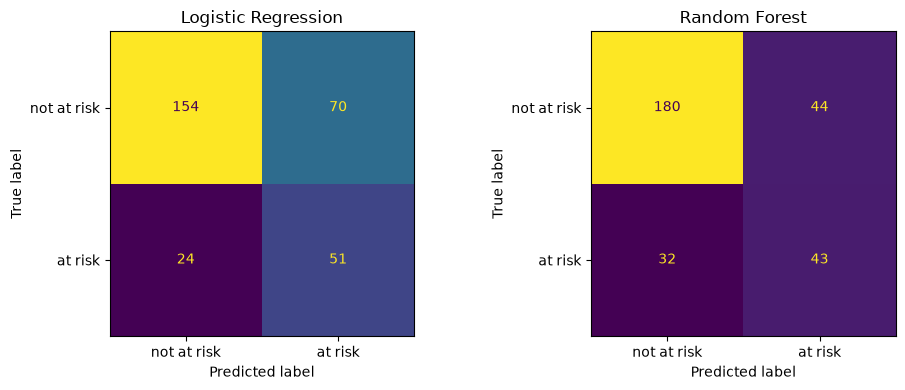

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, result in zip(axes, results):
    ConfusionMatrixDisplay.from_predictions(
        y_test, result["y_pred"], ax=ax, colorbar=False,
        display_labels=["not at risk", "at risk"],
    )
    ax.set_title(result["model"])
fig.tight_layout()
plt.show()

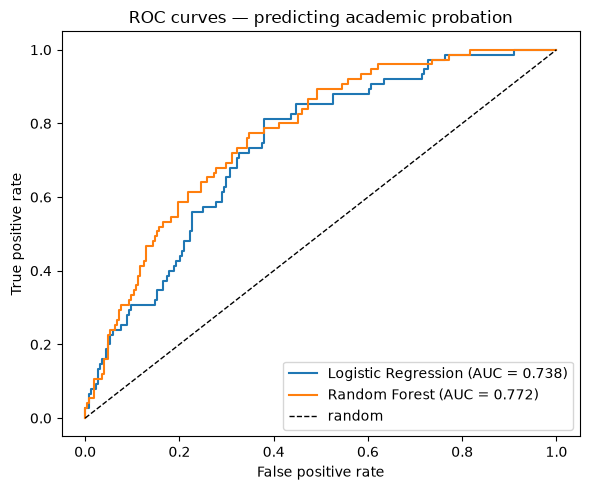

In [12]:
plt.figure(figsize=(6, 5))
for result in results:
    fpr, tpr, _ = roc_curve(y_test, result["y_proba"])
    plt.plot(fpr, tpr, label=f"{result['model']} (AUC = {result['roc_auc']:.3f})")
plt.plot([0, 1], [0, 1], "k--", linewidth=1, label="random")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curves — predicting academic probation")
plt.legend()
plt.tight_layout()
plt.show()

## 8. What drives the predictions

Random Forest feature importance gives the global picture, and SHAP adds
direction: which features push a *specific* student towards or away from risk.

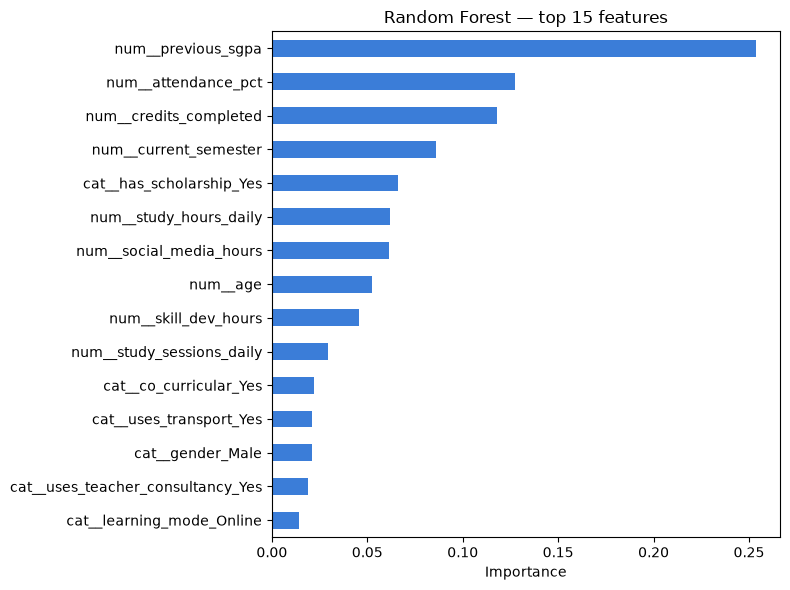

num__previous_sgpa           0.2536
num__attendance_pct          0.1276
num__credits_completed       0.1181
num__current_semester        0.0859
cat__has_scholarship_Yes     0.0663
num__study_hours_daily       0.0619
num__social_media_hours      0.0614
num__age                     0.0527
num__skill_dev_hours         0.0455
num__study_sessions_daily    0.0294


In [13]:
importances = pd.Series(forest.feature_importances_, index=feature_names).sort_values(ascending=False)
top_importances = importances.head(15).sort_values()

plt.figure(figsize=(8, 6))
top_importances.plot.barh(color="#3b7dd8")
plt.xlabel("Importance")
plt.title("Random Forest — top 15 features")
plt.tight_layout()
plt.show()

print(importances.head(10).round(4).to_string())

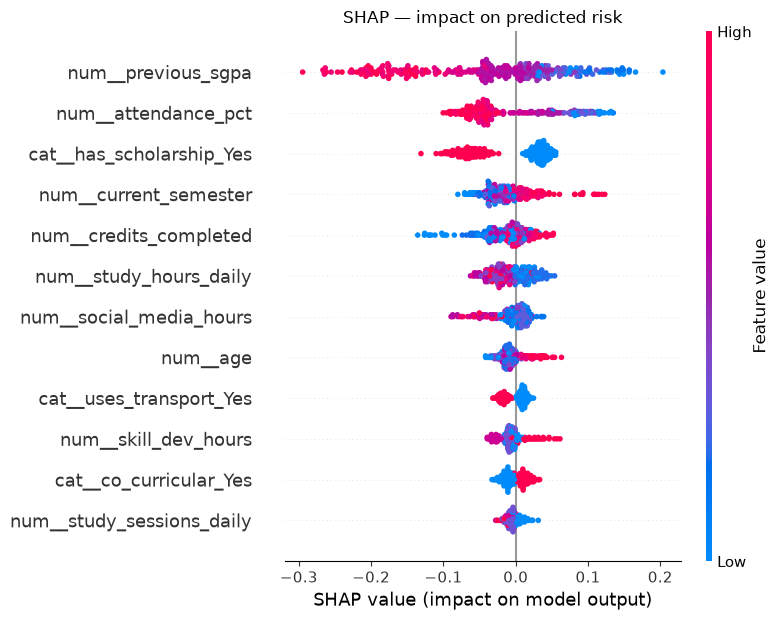

In [14]:
import shap

explainer = shap.TreeExplainer(forest)
shap_values = explainer.shap_values(X_test_t)
if isinstance(shap_values, list):            # older shap: [class_0, class_1]
    shap_values = shap_values[1]
elif shap_values.ndim == 3:                 # newer shap: (rows, features, classes)
    shap_values = shap_values[:, :, 1]

base_value = np.ravel(explainer.expected_value)[1]

shap.summary_plot(shap_values, X_test_t, feature_names=list(feature_names), max_display=12, show=False)
plt.title("SHAP — impact on predicted risk")
plt.tight_layout()
plt.show()

## 9. Example student predictions

Four students from the held-out test set, with the predicted risk and the three
factors that moved the prediction most. Values come from SHAP, so the arrows are
the model's own reasoning for that student, not a generic ranking.

One-hot encoded columns are shown with the student's raw answer, for example
`has_scholarship_Yes (student's has_scholarship = No)`. These columns are
relative to the dropped reference category, so a `0` can still carry a non-zero
contribution.

In [15]:
def describe_feature(feature_name, raw_row):
    # 'cat__gender_Male' -> readable text for one student
    base = feature_name.split("__", 1)[1]
    if base in raw_row.index:
        return f"{base} = {raw_row[base]}"
    for column in raw_row.index:
        if base.startswith(f"{column}_"):
            return f"{base} (student's {column} = {raw_row[column]})"
    return base


def risk_band(probability):
    if probability >= 0.6:
        return "HIGH"
    if probability >= 0.35:
        return "MEDIUM"
    return "LOW"


test_frame = X_test.reset_index(drop=True)
probabilities = results[1]["y_proba"]
actuals = y_test.reset_index(drop=True)

# a few of the highest-risk and lowest-risk students
order = np.argsort(probabilities)
examples = list(order[-3:][::-1]) + list(order[:2])

for row in examples:
    probability = probabilities[row]
    print(f"Student #{row + 1} — predicted risk {probability:.2f} ({risk_band(probability)})"
          f" | actual: {'at risk' if actuals[row] else 'not at risk'}")
    contributions = pd.Series(shap_values[row], index=feature_names)
    for feature_name, value in contributions.reindex(contributions.abs().sort_values(ascending=False).index)[:3].items():
        arrow = "raises risk" if value > 0 else "lowers risk"
        print(f"    {describe_feature(feature_name, test_frame.iloc[row]):<70} {arrow} ({value:+.3f})")
    print()

Student #56 — predicted risk 0.80 (HIGH) | actual: at risk
    previous_sgpa = 1.44                                                   raises risk (+0.121)
    has_scholarship_Yes (student's has_scholarship = No)                   raises risk (+0.048)
    attendance_pct = 83.0                                                  raises risk (+0.035)

Student #12 — predicted risk 0.80 (HIGH) | actual: at risk
    previous_sgpa = 1.21                                                   raises risk (+0.144)
    attendance_pct = 31.0                                                  raises risk (+0.087)
    has_scholarship_Yes (student's has_scholarship = No)                   raises risk (+0.037)

Student #181 — predicted risk 0.79 (HIGH) | actual: not at risk
    previous_sgpa = 1.55                                                   raises risk (+0.103)
    attendance_pct = 66.0                                                  raises risk (+0.086)
    has_scholarship_Yes (student's has_scholarsh

## 10. Takeaways and limitations

**What works.** Attendance, previous SGPA and study behaviour together separate
at-risk students well above a coin flip, and both models agree on the ranking of
the important signals. The at-risk rate falls steadily as attendance rises,
which is the behaviour EduPulse depends on.

**What to keep in mind.**

- The label is self-reported and covers *any* time in the student's past, so the
  model is closer to "who is generally struggling" than "who will fail next term".
- The survey is a single snapshot of CSE students; it is not VIT data and does
  not generalise on its own.
- The school-level and Tamil Nadu datasets are included for exploration and are
  not modelled here.
- Real deployment would need per-term attendance and internal marks feeding the
  same pipeline, plus a check on how stable the thresholds are across cohorts.

Next steps for the dashboard: reuse this feature list and model as an API, not as
a notebook.